<a href="https://colab.research.google.com/github/Madihasafi/ITC-300-Data-Visualization-/blob/main/Madiha_Safi%2C_w10p2_Distributional_Analysis_with_Discrete_Data_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ITC 300: Data Visualization
## **Laboratory Work: Distributional Analysis with Discrete Data**


This laboratory converts discrete-data questions into numerical summaries and appropriate visualizations.

The workflow begins with dataset inspection, then develops frequency tables, bar charts, categorical dot plots, pie charts, and a normalized radar plot.



## **Learning outcomes**

After completing this laboratory, you should be able to:

- load and inspect `Salaries.csv` with pandas;
- identify low-cardinality discrete variables;
- calculate counts, proportions, percentages, and cross-tabulations;
- create vertical, horizontal, grouped, stacked, and 100% stacked bar charts;
- create and interpret a categorical dot plot;
- evaluate when a pie chart gives a valid part-to-whole view;
- aggregate and normalize indicators for a radar plot;
- match the visualization to the analytical question and verify it against the numerical table.


## Part 1: Preparing the analysis environment


We use four libraries:

- **pandas** for DataFrames, frequency tables, cross-tabulations, and grouped summaries;
- **NumPy** for numerical arrays and radar-chart angles;
- **Matplotlib** for figures, axes, annotations, pie charts, and polar coordinates;
- **Seaborn** for a consistent statistical-graphics theme.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Analysis environment is ready.")


Analysis environment is ready.


### Load `Salaries.csv`

The next cell works in both Google Colab and a local Jupyter environment.

- If `Salaries.csv` already exists in the notebook's working folder, pandas loads it directly.
- If the file is absent in Google Colab, an upload dialog appears. Select the provided `Salaries.csv` file.


In [2]:
from pathlib import Path

data_path = Path("Salaries.csv")

if not data_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        if "Salaries.csv" in uploaded:
            data_path = Path("Salaries.csv")
        elif uploaded:
            data_path = Path(next(iter(uploaded)))
        else:
            raise FileNotFoundError("No file was uploaded.")
    except ImportError as exc:
        raise FileNotFoundError(
            "Place Salaries.csv in the notebook's working directory and rerun this cell."
        ) from exc

df = pd.read_csv(data_path)

# Some CSV exports save the row index as an extra column.
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print(f"Loaded: {data_path.name}")
print(f"Analytical shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())


Saving Salaries.csv to Salaries.csv
Loaded: Salaries.csv
Analytical shape: 397 rows × 6 columns


,rank,discipline,yrs.since.phd,yrs.service,sex,salary
0,Prof,B,19,18,Male,139750
1,Prof,B,20,16,Male,173200
2,AsstProf,B,4,3,Male,79750
3,Prof,B,45,39,Male,115000
4,Prof,B,40,41,Male,141500


The expected analytical dataset contains **397 faculty records** and six variables. The first inspection confirms that the file loaded successfully and that the exported index column does not remain in the analysis.


### Inspect columns, data types, and structure


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())

print("\nDataFrame information:")
df.info()


Column names:
['rank', 'discipline', 'yrs.since.phd', 'yrs.service', 'sex', 'salary']

Data types:


,dtype
rank,object
discipline,object
yrs.since.phd,int64
yrs.service,int64
sex,object
salary,int64



DataFrame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   rank           397 non-null    object
 1   discipline     397 non-null    object
 2   yrs.since.phd  397 non-null    int64 
 3   yrs.service    397 non-null    int64 
 4   sex            397 non-null    object
 5   salary         397 non-null    int64 
dtypes: int64(3), object(3)
memory usage: 18.7+ KB


`rank`, `discipline`, and `sex` are stored as object values and define discrete groups. `salary`, `yrs.service`, and `yrs.since.phd` are numerical. We will keep the numerical variables numeric and summarize them within groups when needed.


### Check missing values and category cardinality


In [4]:
column_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(dropna=True)
})

display(column_summary)


,dtype,missing,unique
rank,object,0,3
discipline,object,0,2
yrs.since.phd,int64,0,53
yrs.service,int64,0,52
sex,object,0,2
salary,int64,0,371


**Interpretation:** Low-cardinality variables suit category charts because they contain a small number of distinct groups. A variable such as `salary`, with many distinct values, should not be treated as a nominal category merely because it contains repeated numbers.


### Validate the required variables


In [5]:
required_columns = {
    "rank", "discipline", "yrs.since.phd",
    "yrs.service", "sex", "salary"
}
missing_columns = required_columns.difference(df.columns)

assert not missing_columns, f"Missing required columns: {sorted(missing_columns)}"
assert len(df) > 0, "The dataset contains no rows."

print("Dataset validation passed.")


Dataset validation passed.


## Part 2: Frequency and proportional analysis


For a discrete variable with total sample size $n$:

$$\text{Proportion}_i = \frac{\text{Count}_i}{n}$$

$$\text{Percentage}_i = \text{Proportion}_i \times 100$$

The following reusable function calculates all three forms. An optional category order preserves an ordinal sequence such as Assistant Professor, Associate Professor, and Professor.


In [6]:
def frequency_table(series, category_order=None):
    # Return count, proportion, and percentage for a discrete variable.
    counts = series.value_counts(dropna=False)
    if category_order is not None:
        counts = counts.reindex(category_order, fill_value=0)

    result = counts.rename("count").to_frame()
    result["proportion"] = result["count"] / result["count"].sum()
    result["percent"] = result["proportion"] * 100
    result.index.name = series.name
    return result


rank_order = ["AsstProf", "AssocProf", "Prof"]
rank_frequency = frequency_table(df["rank"], rank_order)
display(rank_frequency)


,count,proportion,percent
rank,,,
AsstProf,67,0.17,16.88
AssocProf,64,0.16,16.12
Prof,266,0.67,67.00


### Validate the frequency table


In [7]:
print("Count total:", rank_frequency["count"].sum())
print("Proportion total:", rank_frequency["proportion"].sum())
print("Percentage total:", rank_frequency["percent"].sum())

assert rank_frequency["count"].sum() == len(df)
assert np.isclose(rank_frequency["proportion"].sum(), 1.0)
assert np.isclose(rank_frequency["percent"].sum(), 100.0)


Count total: 397
Proportion total: 1.0
Percentage total: 100.0


## Part 3: Guided laboratory exercises


### **Exercise 1: Frequency distribution of sex**

Use the reusable `frequency_table()` function to answer:

1. How many faculty records belong to each sex category?
2. What percentage belongs to each category?
3. Which numerical representation makes the imbalance easiest to communicate?


,count,proportion,percent
sex,,,
Male,358,0.90,90.18
Female,39,0.10,9.82


Total faculty records: 397
Largest category: Male (358 records, 90.18%)


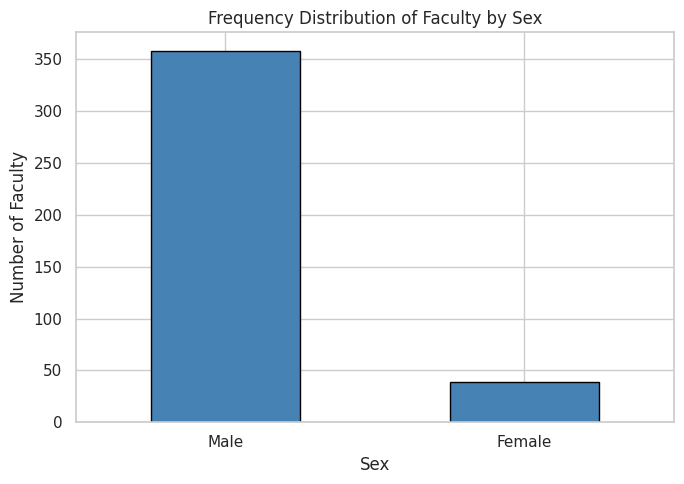

In [9]:
# Exercise 1 solution

sex_frequency = frequency_table(df["sex"])

display(sex_frequency.round(2))

# Identify the category with the highest count
largest_category = sex_frequency["count"].idxmax()
largest_count = sex_frequency.loc[largest_category, "count"]
largest_percent = sex_frequency.loc[largest_category, "percent"]

print(f"Total faculty records: {sex_frequency['count'].sum()}")
print(
    f"Largest category: {largest_category} "
    f"({largest_count} records, {largest_percent:.2f}%)"
)

# Bar chart of faculty counts by sex
ax = sex_frequency["count"].plot(
    kind="bar",
    figsize=(7, 5),
    color="steelblue",
    edgecolor="black"
)

ax.set_title("Frequency Distribution of Faculty by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Number of Faculty")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


### **Exercise 2: Discipline composition within academic rank**

Create a row-percentage cross-tabulation of `rank` and `discipline`. Every row should total 100%. Then identify which rank has the highest percentage of Discipline B.


Counts by rank and discipline:


discipline,A,B
rank,,
AsstProf,24,43
AssocProf,26,38
Prof,131,135


Row percentages by rank:


discipline,A,B
rank,,
AsstProf,35.82,64.18
AssocProf,40.62,59.38
Prof,49.25,50.75


Percentage total for each rank:
rank
AsstProf    100.00
AssocProf   100.00
Prof        100.00
dtype: float64
Highest percentage of Discipline B: AsstProf (64.18%)


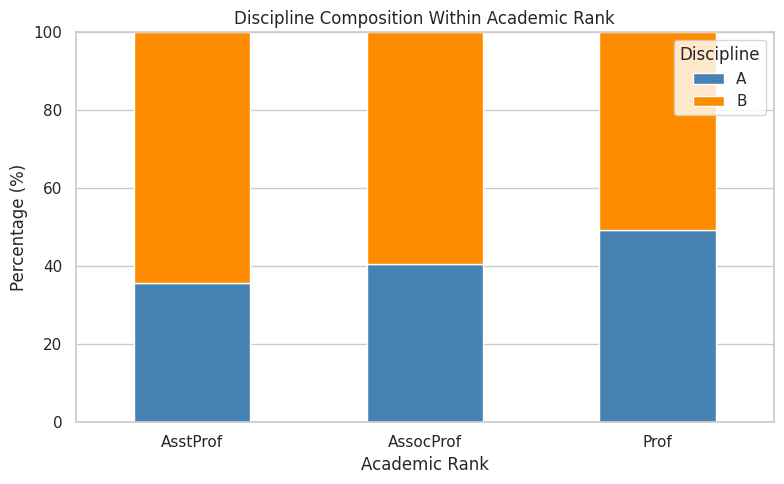

In [10]:
# Exercise 2 solution

# Preserve the academic career-stage order
rank_order = ["AsstProf", "AssocProf", "Prof"]
discipline_order = ["A", "B"]

# Calculate counts for each rank-discipline combination
rank_discipline_counts = pd.crosstab(
    df["rank"],
    df["discipline"]
).reindex(
    index=rank_order,
    columns=discipline_order,
    fill_value=0
)

# Convert each row to percentages
rank_discipline_percent = (
    rank_discipline_counts
    .div(rank_discipline_counts.sum(axis=1), axis=0)
    .mul(100)
)

print("Counts by rank and discipline:")
display(rank_discipline_counts)

print("Row percentages by rank:")
display(rank_discipline_percent.round(2))

# Verify that every row totals 100%
print("Percentage total for each rank:")
print(rank_discipline_percent.sum(axis=1).round(2))

# Find the rank with the highest percentage of Discipline B
highest_rank = rank_discipline_percent["B"].idxmax()
highest_percent = rank_discipline_percent.loc[highest_rank, "B"]

print(
    f"Highest percentage of Discipline B: {highest_rank} "
    f"({highest_percent:.2f}%)"
)

# Visualize the row percentages
ax = rank_discipline_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["steelblue", "darkorange"],
    edgecolor="white"
)

ax.set_title("Discipline Composition Within Academic Rank")
ax.set_xlabel("Academic Rank")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Discipline")

plt.tight_layout()
plt.show()



### **Exercise 3: Mean salary by academic rank**

Academic rank is discrete, while salary is numerical. Aggregate salary by rank, then create a labeled horizontal bar chart. Keep the career-stage order rather than sorting by salary.


Mean salary by academic rank:


,Mean Salary
rank,
AsstProf,"80,775.99"
AssocProf,"93,876.44"
Prof,"126,772.11"


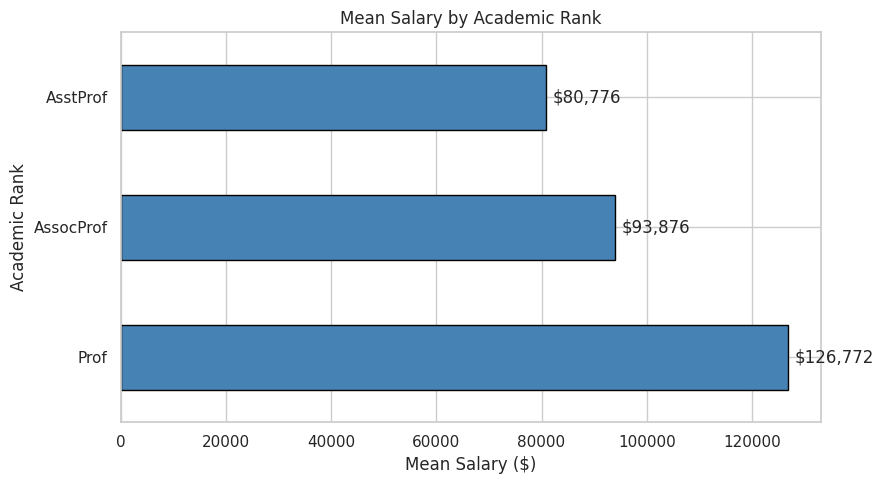

In [11]:
# Exercise 3 solution

rank_order = ["AsstProf", "AssocProf", "Prof"]

# Calculate mean salary for each rank in the required order
mean_salary = (
    df.groupby("rank")["salary"]
    .mean()
    .reindex(rank_order)
)

print("Mean salary by academic rank:")
display(mean_salary.rename("Mean Salary").to_frame().round(2))

# Create a horizontal bar chart
ax = mean_salary.plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue",
    edgecolor="black"
)

# Add salary labels to the bars
for bar in ax.patches:
    width = bar.get_width()
    ax.annotate(
        f"${width:,.0f}",
        xy=(width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

ax.set_title("Mean Salary by Academic Rank")
ax.set_xlabel("Mean Salary ($)")
ax.set_ylabel("Academic Rank")

# Display Assistant Professor first, then Associate Professor, then Professor
ax.invert_yaxis()

plt.tight_layout()
plt.show()


### **Exercise 4: Chart-choice critique**

For each situation, write the chart you would select and justify the choice in one or two sentences.

1. Compare exact faculty counts across the three academic ranks.
2. Compare the percentage of Female and Male faculty within each rank.
3. Present the two-discipline composition to a general audience.
4. Compare five normalized discipline indicators in a compact overview.

**Reflection:** When would you replace the radar plot with grouped bars or small multiples?


**Provide your answer here**

1. Compare exact faculty counts across the three academic ranks.

I would use a bar chart because if the number of faculty members in each academic rank is easy to compare. The length or height of each bar refers to the number of items in each bar and will make it easy for readers to see the difference between the three ranks.

 2. Compare the percentage of Female and Male faculty within each rank.

If the faculty information shows the percentage composition of faculty within each academic rank, then I would use a 100% stacked bar chart. Each bar is 100% and comparisons are easier across ranks despite the varying sample sizes.

 3. Present the two-discipline composition to a general audience.

I would use a pie chart if I wanted to display the percentage of total faculty members that are from Discipline A and Discipline B. The chart can be used to convey the part-to-whole relationship without any complexity since there are only two categories. If the audience requires the exact percentages compared with each other more precisely, however, a bar chart would be better.

 4. Compare five normalized discipline indicators in a compact overview.

If I wanted to present 5 indicators, normalized to the same scale (and a single graph), I would use a radar plot. It can give an overall picture of the relative strengths and weaknesses of the indicators. All indicators, however, should be plotted on a similar scale before overlaying, and the graph should be read with caution due to the possible lack of differentiation between overlapping shapes.

 Reflection: When would you replace the radar plot with grouped bars or small multiples?

I would use the radar plot if I wanted to show an overall profile but if I wanted to make exact comparison of indicators or groups I would use the grouped bars. Grouped bars are helpful when there is a common base for the values, allowing differences to be identified more easily. If there are a number of groups or indicators, then I would use small multiples since the patterns would be less cluttered by having separate charts. In general, the decision will depend on whether the primary purpose is to demonstrate a general trend or to make accurate comparisons between individual values.